In [29]:
import numpy as np
from scipy.linalg import eigh
from scipy.integrate import solve_ivp
from scipy.constants import e, hbar, h

from transmon_func import transmon_hamiltonian

import matplotlib.pyplot as plt

In [30]:
# Defined a transmon based on the physical parameters

C = 70e-15       # 70 fF
Ic = 40e-9       # 40 nA

EC = e**2 / (2*C)
EJ = hbar*Ic / (2*e)

print("EC/h =", f"{EC/h:.4e}", "Hz")
print("EJ/h =", f"{EJ/h:.4e}", "Hz")
print("EJ/EC =", EJ/EC)

N=20
H = transmon_hamiltonian(EJ, EC, N=N)

EC/h = 2.7672e+08 Hz
EJ/h = 1.9867e+10 Hz
EJ/EC = 71.79645665858247


In [31]:
# Transforming the charge operator into the energy basis to see what states are strongly coupled

# Charge basis
n = np.arange(-N, N + 1)

# Charge operator
n_operator = np.diag(n)

# Diagonalize the static Hamiltonian
energies, states = eigh(H)

# Retain the lowest energy levels
n_levels = 6
V = states[:, :n_levels]

# Transform charge operator into energy basis
n_energy = V.conj().T @ n_operator @ V

print("Charge matrix elements:")
print(np.round(n_energy, 3))

Charge matrix elements:
[[-0.000e+00 -1.197e+00  0.000e+00  3.500e-02 -0.000e+00 -2.000e-03]
 [-1.197e+00  0.000e+00  1.650e+00  0.000e+00 -7.500e-02  0.000e+00]
 [ 0.000e+00  1.650e+00  0.000e+00 -1.962e+00  0.000e+00  1.300e-01]
 [ 3.500e-02  0.000e+00 -1.962e+00 -0.000e+00  2.186e+00 -0.000e+00]
 [-0.000e+00 -7.500e-02  0.000e+00  2.186e+00 -0.000e+00 -2.332e+00]
 [-2.000e-03  0.000e+00  1.300e-01 -0.000e+00 -2.332e+00  0.000e+00]]


The transmon Hamiltonian:

$$
\hat H_0 =
4E_C(\hat n-n_g)^2-E_J\cos\hat\varphi.
$$

But now the offset voltage is being driven:

$$
n_g(t)=n_g^{(0)}+n_g^{(ac)}\cos(\omega_d t)
$$

where:
- $n_g^{(0)}$ is the static offset charge.
- $n_g^{(ac)}$ is the drive amplitude, expressed in Cooper-pair charge units.
- $\omega_d$ is the angular frequency of the microwave signal.

The Hamiltonian becomes:

$$
H(t)=4E_C
\left[
n-n_g^{(0)}-n_g^{(ac)}\cos(\omega_dt)
\right]^2
-E_J\cos\varphi
$$

Expanding:
$$
\begin{aligned}
H(t)=&4E_C(n-n_g^{(0)})^2-E_J\cos\varphi\\
&-8E_C(n-n_g^{(0)})n_g^{(ac)}
\cos(\omega_dt)\\
&+4E_C(n_g^{(ac)})^2\cos^2(\omega_dt).
\end{aligned}
$$

We can separate this into:
$$
H(t)=H_0+H_{\mathrm{drive}}(t)
$$

Ignoring the terms contributing only a global phase, we obtain
$$
H_{\mathrm{drive}}(t)=
-8E_Cn_g^{(ac)}\hat n
\cos(\omega_dt)
$$

In [32]:
# The transmon Hamiltonian directly in the energy basis with an addition of the drive microwave energy

def driven_hamiltonian(t, energies, n_energy,
                       EC, ng_ac, omega_d):

    H0 = np.diag(energies)

    H_drive = (
        -8 * EC * ng_ac
        * np.cos(omega_d * t)
        * n_energy
    )

    return H0 + H_drive

Solving the time-dependent Shrodinger equation:

$$
\frac{d}{dt}|\psi(t)\rangle
=
-\frac{i}{\hbar}H(t)|\psi(t)\rangle.
$$

In [33]:
def schrodinger_equation(t, psi, energies,
                        n_energy, EC, ng_ac, omega_d):

    H = driven_hamiltonian(
        t, energies, n_energy,
        EC, ng_ac, omega_d
    )

    return -1j / hbar * H @ psi

In [34]:
# Initializing the ground state
psi0 = np.zeros(n_levels, dtype=complex)
psi0[0] = 1.0

# Defining the driving frequency as the 01 transition frequency
# Solving the equation with a different driving frequency, we will clearly see a lack of popuation oscillations
omega_d = (energies[1] - energies[0]) / hbar

# Drive amplitude
# Should linearly affect the Rabi oscillations frequency
ng_ac = 0.001

t_max = 500e-9

times = np.linspace(0, t_max, 700)

# Solving the time evolution
solution = solve_ivp(
    schrodinger_equation,
    (0, t_max),
    psi0,
    t_eval=times,
    args=(
        energies[:n_levels],
        n_energy,
        EC,
        ng_ac,
        omega_d
    ),
    method="DOP853",
    max_step=1 / (40 * omega_d / (2*np.pi)),
    rtol=1e-8,
    atol=1e-10
)

states = solution.y.T

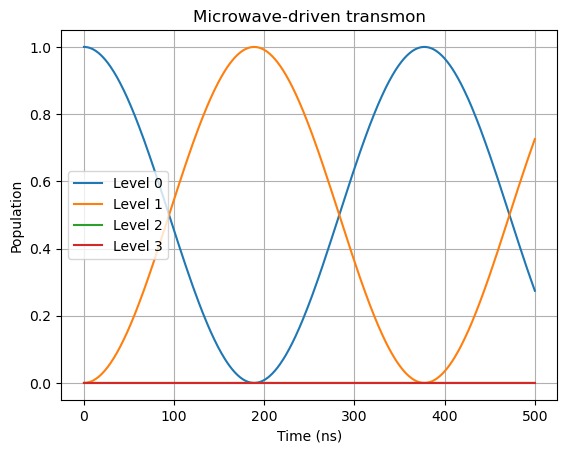

In [35]:
# Plotting the populations in relation to time

populations = np.abs(states)**2

for m in range(4):
    plt.plot(
        times * 1e9,
        populations[:, m],
        label=f"Level {m}"
    )

plt.xlabel("Time (ns)")
plt.ylabel("Population")
plt.title("Microwave-driven transmon")
plt.legend()
plt.grid()
plt.show()

In [36]:
# Checking the population leakage into higher levels

P_leak = 1 - populations[:, 0] - populations[:, 1]

print("Maximum leakage:", np.max(P_leak))

Maximum leakage: 3.691886881096451e-05


### Rabi oscillation model

For a resonant, sufficiently weak drive, the two-level approximation gives:

$$
P_1(t)=\sin^2\left(\frac{\Omega_Rt}{2}\right).
$$

The angular Rabi frequency is

$$
\Omega_R=
\frac{8E_Cn_g^{(ac)}}{\hbar}
|\langle0|\hat n|1\rangle|
$$

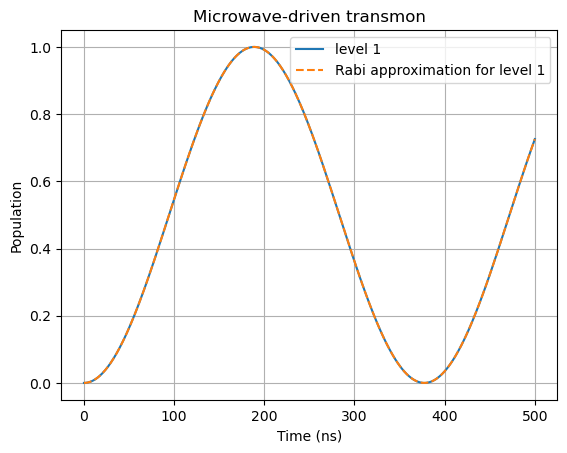

Max error: 4.5376424451912955e-05


C:\Users\pauls\AppData\Local\Temp\ipykernel_23072\1372542406.py:18: RuntimeWarning: invalid value encountered in scalar divide
  errors = abs(rabi_approx[value] - populations[:, 1][value])/rabi_approx[value]


In [37]:
# Comparing level 1 populations to the Rabi approximation

plt.plot(times*1e9, populations[:, 1], label="level 1")

rabi_freq = (8*EC*ng_ac)/hbar * abs(n_energy[0,1])
rabi_approx = (np.sin(rabi_freq*times/2))**2
plt.plot(times*1e9, rabi_approx, '--', label='Rabi approximation for level 1')

plt.xlabel("Time (ns)")
plt.ylabel("Population")
plt.title("Microwave-driven transmon")
plt.legend()
plt.grid()
plt.show()

errors = np.array([])
for value in range(len(rabi_approx)):
    errors = abs(rabi_approx[value] - populations[:, 1][value])/rabi_approx[value]
print(f"Max error: {errors.max()}")

ng_ac = 0.0005, maximum leakage = 5.158624341694562e-06
ng_ac = 0.002, maximum leakage = 0.00014621373273560057
ng_ac = 0.01, maximum leakage = 0.003932973894269831


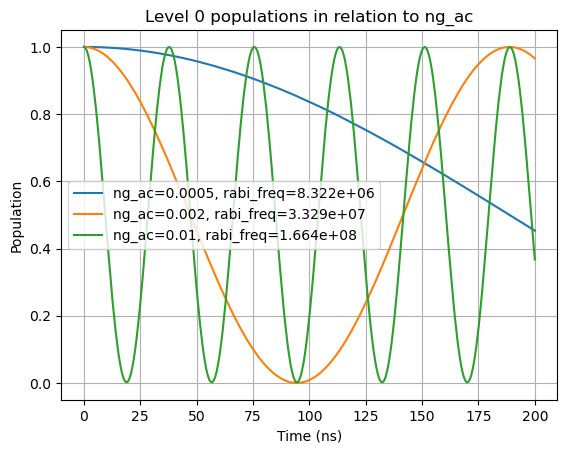

In [40]:
# Checking that the driving amplitude directly corresponds to the population oscillation frequency

ng_values = [0.0005, 0.002, 0.01]
t_max = 200e-9
times = np.linspace(0, t_max, 300)

for amplitude in ng_values:
    
    solution = solve_ivp(
    schrodinger_equation,
    (0, t_max),
    psi0,
    t_eval=times,
    args=(
        energies[:n_levels],
        n_energy,
        EC,
        amplitude,
        omega_d
    ),
    method="DOP853",
    max_step=1 / (40 * omega_d / (2*np.pi)),
    rtol=1e-8,
    atol=1e-10
    )

    populations = abs(solution.y.T)**2

    P_leak = 1 - populations[:, 0] - populations[:, 1]
    print(f"ng_ac = {amplitude}, maximum leakage = {np.max(P_leak)}")

    rabi_freq = (8*EC*amplitude)/hbar * abs(n_energy[0,1])
    plt.plot(times*1e9, populations[:,0], label=f"ng_ac={amplitude}, rabi_freq={rabi_freq:.3e}")

plt.title("Level 0 populations in relation to ng_ac")
plt.xlabel("Time (ns)")
plt.ylabel("Population")

plt.legend()
plt.grid()
plt.show()

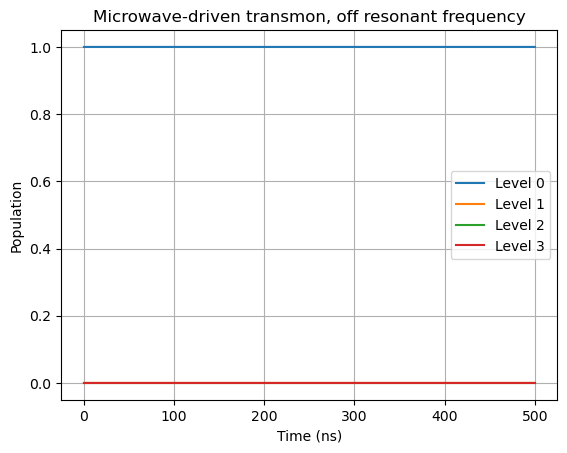

In [44]:
# As an experiment, let's choose a different driving frequency. We're supposed to see no population oscillation

# Initializing the ground state
psi0 = np.zeros(n_levels, dtype=complex)
psi0[0] = 1.0

# Defining the driving frequency as the 01 transition frequency times 1.2
omega_d = (energies[1] - energies[0]) / hbar * 1.2

# Drive amplitude
ng_ac = 0.001

t_max = 500e-9

times = np.linspace(0, t_max, 700)

# Solving the time evolution
solution = solve_ivp(
    schrodinger_equation,
    (0, t_max),
    psi0,
    t_eval=times,
    args=(
        energies[:n_levels],
        n_energy,
        EC,
        ng_ac,
        omega_d
    ),
    method="DOP853",
    max_step=1 / (40 * omega_d / (2*np.pi)),
    rtol=1e-8,
    atol=1e-10
)

states = solution.y.T

# Plotting the populations in relation to time

populations = np.abs(states)**2

for m in range(4):
    plt.plot(
        times * 1e9,
        populations[:, m],
        label=f"Level {m}"
    )

plt.xlabel("Time (ns)")
plt.ylabel("Population")
plt.title("Microwave-driven transmon, off resonant frequency")
plt.legend()
plt.grid()
plt.show()

In [43]:
print(f"Max level 1 population: {populations[:, 1].max()}")

Max level 1 population: 4.288738625318476e-06
